In [1]:
import pandas as pd
import matplotlib.pyplot as plt

### Aircraft Position

In [141]:
aircraft_state = pd.read_csv("aircraft_state.csv")

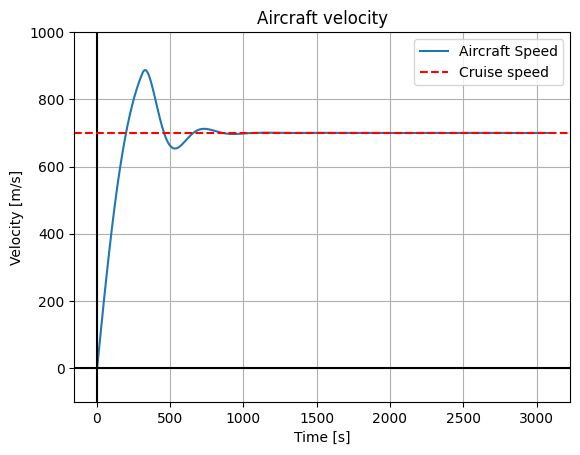

In [149]:
import matplotlib.pyplot as plt

plt.plot(aircraft_state["time"], aircraft_state["vel"], label="Aircraft Speed")

plt.xlabel("Time [s]")
plt.ylabel("Velocity [m/s]")
plt.title("Aircraft velocity")

# plt.axis("equal")  # Usually not recommended for Time vs Velocity plots as it distorts the scale

# Set Y-axis limits
plt.ylim(-100, 1000)

plt.grid(True)
plt.axvline(x=0, color='black')
plt.axhline(y=0, color='black')
plt.axhline(y=700, color='red',linestyle="--", label="Cruise speed")
plt.legend()
plt.show()

Maximum Velocity: 887.16 m/s
First time reaching 500 m/s: 128.00 s
Settling Time (±0.3% of 700.0 m/s): 990.00 seconds


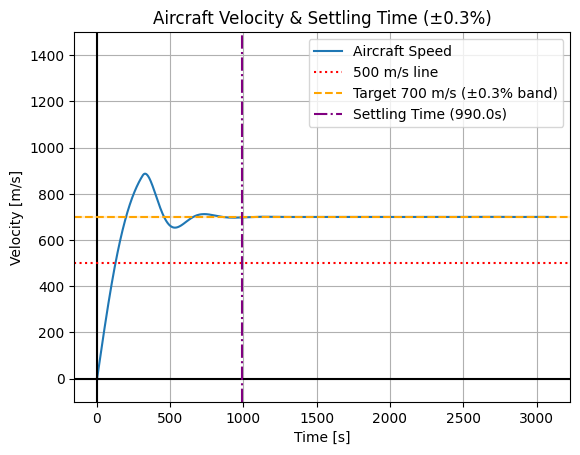

In [142]:
import matplotlib.pyplot as plt
import numpy as np

# Convert to numpy arrays
times = np.array(aircraft_state["time"])
vels = np.array(aircraft_state["vel"])

target_vel = 700.0
tolerance = 0.003  # 0.5% settling band
lower_bound = target_vel * (1 - tolerance)  # 696.5 m/s
upper_bound = target_vel * (1 + tolerance)  # 703.5 m/s

# 1. Calculate Maximum Velocity
max_vel = np.max(vels)
print(f"Maximum Velocity: {max_vel:.2f} m/s")

# 2. Find First Time Reaching 500 m/s
reaching_500_indices = np.where(vels >= 500)[0]
if len(reaching_500_indices) > 0:
  print(f"First time reaching 500 m/s: {times[reaching_500_indices[0]]:.2f} s")

# 3. Calculate Settling Time for 700 m/s (Control Theory Definition: stays within ±0.5%)
settling_time = None
for i in range(len(vels) - 1, -1, -1):
  if not (lower_bound <= vels[i] <= upper_bound):
    if i < len(vels) - 1:
      settling_time = times[i + 1]
    break
else:
  settling_time = times[0]  # If it started within the band

if settling_time is not None:
  print(
      f"Settling Time (±0.3% of {target_vel} m/s): {settling_time:.2f} seconds"
  )
else:
  print(f"The aircraft did not settle within ±0.3% of {target_vel} m/s.")

# --- Plotting ---
plt.plot(times, vels, label="Aircraft Speed")

plt.xlabel("Time [s]")
plt.ylabel("Velocity [m/s]")
plt.title("Aircraft Velocity & Settling Time (±0.3%)")

# Set Y-axis limits
plt.ylim(-100, 1500)

plt.grid(True)
plt.axvline(x=0, color="black")
plt.axhline(y=0, color="black")
plt.axhline(y=500, color="red", linestyle=":", label="500 m/s line")
plt.axhline(
    y=700, color="orange", linestyle="--", label="Target 700 m/s (±0.3% band)"
)
plt.axhspan(lower_bound, upper_bound, color="orange", alpha=0.15)

if settling_time is not None:
  plt.axvline(
      x=settling_time,
      color="purple",
      linestyle="-.",
      label=f"Settling Time ({settling_time:.1f}s)",
  )

plt.legend()
plt.show()
plt.show()

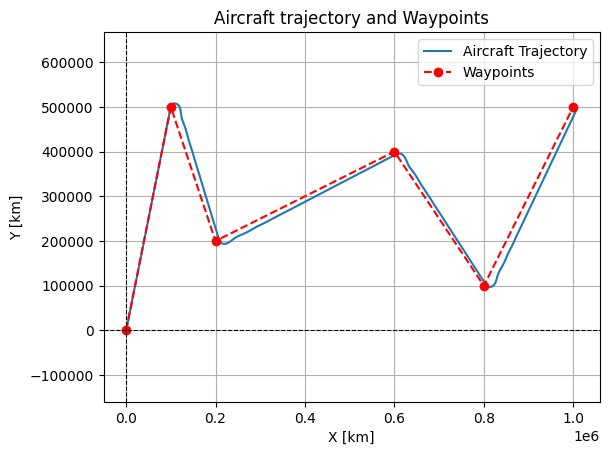

In [130]:
# 1. Define your waypoints in Python (assuming they are in meters, matching your state data)
wp_x = [0.0, 0.1e6, 0.2e6, 0.6e6, 0.8e6, 1e6]
wp_y = [0.0, 5e5, 2e5, 4e5, 1e5, 5e5]
# 2. Plot the aircraft trajectory as before
plt.plot(aircraft_state["x"] / 1, aircraft_state["y"] / 1, label="Aircraft Trajectory")

# 3. Plot the waypoints (divided by 1000 to match km units, with red markers and a dashed line)
plt.plot(
    [x  for x in wp_x], 
    [y  for y in wp_y], 
    'ro--', 
    label="Waypoints",
    linewidth=1.5,
    markersize=6
)

plt.xlabel("X [km]")
plt.ylabel("Y [km]")
plt.title("Aircraft trajectory and Waypoints")
plt.axvline(x=0, color='black', linewidth=0.8, linestyle='--')
plt.axhline(y=0, color='black', linewidth=0.8, linestyle='--')

plt.axis("equal")
plt.grid(True)
plt.legend()

plt.show()

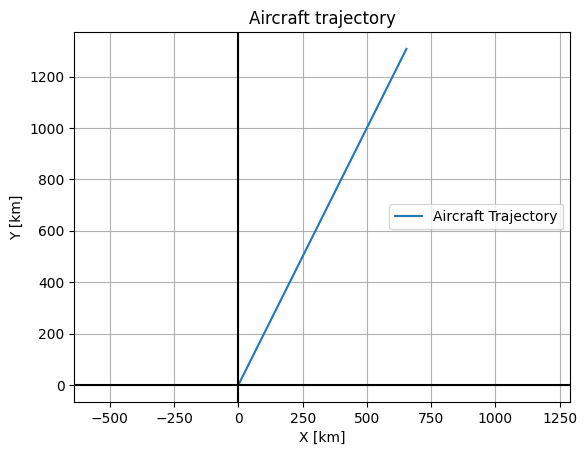

In [14]:

plt.plot(aircraft_state["x"]/1000, aircraft_state["y"]/1000,label="Aircraft Trajectory")
#plt.plot(aircraft_state["gx"]/1000, aircraft_state["gy"]/1000,label="Guidance Trajectory")

plt.xlabel("X [km]")
plt.ylabel("Y [km]")
plt.title("Aircraft trajectory")
plt.axvline(x=0,color='black')
plt.axhline(y=0,color='black')


plt.axis("equal")
plt.grid(True)
plt.legend()

plt.show()